# 13 — Toronto multi-scenario thermal walking network

## Purpose

Notebook 12 created a set of scenario-specific UTCI rasters.

This notebook converts those rasters into **scenario-specific walking-network
thermal costs** while keeping the underlying walking network topology fixed.

For every thermal scenario, it:

1. loads the same U of T walking network;
2. restricts analysis to edges fully covered by the UTCI raster;
3. samples UTCI along edges at regular intervals;
4. calculates edge-level thermal impedance;
5. evaluates λ sensitivity;
6. saves scenario-specific edge tables and GraphML files;
7. summarizes how network thermal cost changes between hot and reference days.

Primary impedance model:

\[
c_e^{heat}
=
t_e
\left[
1 + \lambda \max(UTCI_e - 32, 0)
ight]
\]

λ remains a **sensitivity parameter**, not a behaviorally calibrated coefficient.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import rasterio

from shapely.geometry import LineString, box
from shapely.ops import transform

import osmnx as ox

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

WALK_GRAPH_PATH = (
    TORONTO_RAW
    / "toronto_walk_8km.graphml"
)

SOLWEIG_BATCH_DIR = (
    TORONTO_OUTPUTS
    / "solweig_multiday"
)

SOLWEIG_SUMMARY_PATH = (
    SOLWEIG_BATCH_DIR
    / "toronto_multiday_solweig_summary.csv"
)

THERMAL_NETWORK_DIR = (
    TORONTO_INTERIM
    / "thermal_network_multiday"
)

THERMAL_NETWORK_OUTPUTS = (
    TORONTO_OUTPUTS
    / "thermal_network_multiday"
)

THERMAL_NETWORK_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

THERMAL_NETWORK_OUTPUTS.mkdir(
    parents=True,
    exist_ok=True,
)

print("Walking graph:", WALK_GRAPH_PATH)
print("SOLWEIG summary:", SOLWEIG_SUMMARY_PATH)

Walking graph: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw/toronto_walk_8km.graphml
SOLWEIG summary: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/solweig_multiday/toronto_multiday_solweig_summary.csv


## 2. Thermal-network parameters

In [2]:
WALKING_SPEED_MS = 1.4

UTCI_THRESHOLD_C = 32.0

LAMBDA_REFERENCE = 0.05

LAMBDA_VALUES = [
    0.00,
    0.01,
    0.025,
    0.05,
    0.075,
    0.10,
]

SAMPLE_SPACING_M = 10.0
MIN_SAMPLES_PER_EDGE = 3

print("Walking speed:", WALKING_SPEED_MS, "m/s")
print("UTCI threshold:", UTCI_THRESHOLD_C, "°C")
print("Reference λ:", LAMBDA_REFERENCE)

Walking speed: 1.4 m/s
UTCI threshold: 32.0 °C
Reference λ: 0.05


## 3. Load successful SOLWEIG scenarios

In [3]:
if not SOLWEIG_SUMMARY_PATH.exists():
    raise FileNotFoundError(
        "Notebook 12 summary not found."
    )

scenarios = pd.read_csv(
    SOLWEIG_SUMMARY_PATH
)

scenarios["date"] = pd.to_datetime(
    scenarios["date"]
)

required_cols = [
    "scenario_id",
    "scenario_role",
    "date",
    "utci_raster",
]

missing = [
    col
    for col in required_cols
    if col not in scenarios.columns
]

if missing:
    raise RuntimeError(
        f"Missing scenario columns: {missing}"
    )

print(
    "Successful thermal scenarios:",
    len(scenarios),
)

display(
    scenarios[
        required_cols
    ]
)

Successful thermal scenarios: 14


,scenario_id,scenario_role,date,utci_raster
0,hot_2025-06-22_1500,hot,2025-06-22,/scratch/project_2010417/paper3/heat-condition...
1,reference_2025-06-29_1500,reference,2025-06-29,/scratch/project_2010417/paper3/heat-condition...
2,hot_2025-06-23_1500,hot,2025-06-23,/scratch/project_2010417/paper3/heat-condition...
3,reference_2025-06-16_1500,reference,2025-06-16,/scratch/project_2010417/paper3/heat-condition...
4,hot_2025-06-24_1500,hot,2025-06-24,/scratch/project_2010417/paper3/heat-condition...
5,reference_2025-07-08_1500,reference,2025-07-08,/scratch/project_2010417/paper3/heat-condition...
6,hot_2025-07-06_1500,hot,2025-07-06,/scratch/project_2010417/paper3/heat-condition...
7,reference_2025-07-20_1500,reference,2025-07-20,/scratch/project_2010417/paper3/heat-condition...
8,hot_2025-07-24_1500,hot,2025-07-24,/scratch/project_2010417/paper3/heat-condition...
9,reference_2025-07-03_1500,reference,2025-07-03,/scratch/project_2010417/paper3/heat-condition...


## 4. Load walking network once

In [4]:
if not WALK_GRAPH_PATH.exists():
    raise FileNotFoundError(
        WALK_GRAPH_PATH
    )

G = ox.load_graphml(
    WALK_GRAPH_PATH
)

print(
    "Original nodes:",
    len(G.nodes),
)

print(
    "Original edges:",
    len(G.edges),
)

Original nodes: 35817
Original edges: 96924


## 5. Convert walking graph to projected GeoDataFrames

In [5]:
nodes, edges = ox.graph_to_gdfs(
    G,
    nodes=True,
    edges=True,
    fill_edge_geometry=True,
)

print("Graph CRS:", edges.crs)

if edges.crs is None:
    raise RuntimeError(
        "Walking graph CRS is missing."
    )

# Ensure length is numeric.
edges["length"] = pd.to_numeric(
    edges["length"],
    errors="coerce",
)

edges = edges[
    edges["length"].notna()
    &
    (edges["length"] > 0)
].copy()

print(
    "Usable edges:",
    len(edges),
)

Graph CRS: EPSG:32617
Usable edges: 96924


## 6. Sampling helper

Each edge is sampled at approximately 10 m spacing, with at least three points.

Raster bounds are checked explicitly to prevent the out-of-bounds sampling
issue found in the earlier single-scenario thermal-network notebook.

In [6]:
def sample_edge_utci(
    geometry,
    src,
    spacing_m=SAMPLE_SPACING_M,
    min_samples=MIN_SAMPLES_PER_EDGE,
):

    if geometry is None or geometry.is_empty:
        return np.nan, 0

    length = float(
        geometry.length
    )

    n_samples = max(
        min_samples,
        int(
            np.ceil(
                length / spacing_m
            )
        ) + 1,
    )

    distances = np.linspace(
        0,
        length,
        n_samples,
    )

    points = [
        geometry.interpolate(
            d
        )
        for d in distances
    ]

    coords = []

    for point in points:

        x = float(
            point.x
        )

        y = float(
            point.y
        )

        if (
            src.bounds.left <= x < src.bounds.right
            and
            src.bounds.bottom < y <= src.bounds.top
        ):

            coords.append(
                (
                    x,
                    y,
                )
            )

    if not coords:
        return np.nan, 0

    sampled = np.array(
        [
            value[0]
            for value in src.sample(
                coords
            )
        ],
        dtype=float,
    )

    sampled = sampled[
        np.isfinite(
            sampled
        )
    ]

    if len(sampled) == 0:
        return np.nan, 0

    return (
        float(
            np.mean(sampled)
        ),
        int(
            len(sampled)
        ),
    )

## 7. Build a fixed analysis edge set from the first UTCI raster

The same edge topology must be used across scenarios.

We therefore identify edges fully covered by the first raster footprint, then
reuse exactly that edge set for every remaining scenario.

In [7]:
first_raster_path = Path(
    scenarios.iloc[0][
        "utci_raster"
    ]
)

if not first_raster_path.exists():
    raise FileNotFoundError(
        first_raster_path
    )

with rasterio.open(
    first_raster_path
) as src:

    raster_crs = src.crs

    raster_polygon = gpd.GeoSeries(
        [
            box(
                src.bounds.left,
                src.bounds.bottom,
                src.bounds.right,
                src.bounds.top,
            )
        ],
        crs=raster_crs,
    ).iloc[0]

if edges.crs != raster_crs:

    edges_projected = edges.to_crs(
        raster_crs
    )

    nodes_projected = nodes.to_crs(
        raster_crs
    )

else:

    edges_projected = edges.copy()
    nodes_projected = nodes.copy()

fixed_edges = edges_projected[
    edges_projected.geometry.covered_by(
        raster_polygon
    )
].copy()

fixed_edge_index = set(
    fixed_edges.index
)

fixed_nodes_used = set()

for u, v, k in fixed_edges.index:
    fixed_nodes_used.add(u)
    fixed_nodes_used.add(v)

fixed_nodes = nodes_projected.loc[
    nodes_projected.index.isin(
        fixed_nodes_used
    )
].copy()

print(
    "Fixed nodes:",
    len(fixed_nodes),
)

print(
    "Fixed edges:",
    len(fixed_edges),
)

Fixed nodes: 3984
Fixed edges: 10682


## 8. Prepare invariant edge travel time

In [8]:
fixed_edges[
    "walk_time_s"
] = (
    fixed_edges[
        "length"
    ]
    / WALKING_SPEED_MS
)

print(
    "Mean edge length:",
    round(
        fixed_edges[
            "length"
        ].mean(),
        2,
    ),
    "m",
)

print(
    "Mean walk time:",
    round(
        fixed_edges[
            "walk_time_s"
        ].mean(),
        2,
    ),
    "s",
)

Mean edge length: 31.8 m
Mean walk time: 22.72 s


## 9. Sample UTCI for every scenario

Scenario-specific edge tables are saved immediately.

In [9]:
scenario_summary_rows = []

for i, row in scenarios.iterrows():

    scenario_id = str(
        row[
            "scenario_id"
        ]
    )

    scenario_role = str(
        row[
            "scenario_role"
        ]
    )

    scenario_date = pd.Timestamp(
        row[
            "date"
        ]
    )

    raster_path = Path(
        row[
            "utci_raster"
        ]
    )

    print()
    print(
        "=" * 72
    )

    print(
        f"[{i + 1}/{len(scenarios)}] "
        f"{scenario_id}"
    )

    if not raster_path.exists():
        print(
            "Missing raster — skipped."
        )
        continue

    scenario_edges = (
        fixed_edges.copy()
    )

    edge_utci = []
    sample_counts = []

    with rasterio.open(
        raster_path
    ) as src:

        raster_min = float(
            np.nanmin(
                src.read(1)
            )
        )

        raster_max = float(
            np.nanmax(
                src.read(1)
            )
        )

        for geom in scenario_edges.geometry:

            mean_utci, n_samples = (
                sample_edge_utci(
                    geom,
                    src,
                )
            )

            edge_utci.append(
                mean_utci
            )

            sample_counts.append(
                n_samples
            )

    scenario_edges[
        "utci_1500"
    ] = edge_utci

    scenario_edges[
        "utci_sample_n"
    ] = sample_counts

    scenario_edges = scenario_edges[
        scenario_edges[
            "utci_1500"
        ].notna()
    ].copy()

    if scenario_edges.empty:
        print(
            "No valid sampled edges — skipped."
        )
        continue

    edge_min = float(
        scenario_edges[
            "utci_1500"
        ].min()
    )

    edge_max = float(
        scenario_edges[
            "utci_1500"
        ].max()
    )

    if edge_min < raster_min - 1e-6:
        raise RuntimeError(
            f"{scenario_id}: edge UTCI below raster min."
        )

    if edge_max > raster_max + 1e-6:
        raise RuntimeError(
            f"{scenario_id}: edge UTCI above raster max."
        )

    scenario_edges[
        "heat_excess"
    ] = np.maximum(
        scenario_edges[
            "utci_1500"
        ]
        - UTCI_THRESHOLD_C,
        0,
    )

    # Reference lambda
    scenario_edges[
        "thermal_cost_s"
    ] = (
        scenario_edges[
            "walk_time_s"
        ]
        * (
            1
            +
            LAMBDA_REFERENCE
            * scenario_edges[
                "heat_excess"
            ]
        )
    )

    scenario_edges[
        "cost_ratio"
    ] = (
        scenario_edges[
            "thermal_cost_s"
        ]
        / scenario_edges[
            "walk_time_s"
        ]
    )

    # Lambda sensitivity fields
    for lam in LAMBDA_VALUES:

        suffix = str(
            lam
        ).replace(
            ".",
            "_"
        )

        scenario_edges[
            f"thermal_cost_lambda_{suffix}"
        ] = (
            scenario_edges[
                "walk_time_s"
            ]
            * (
                1
                +
                lam
                * scenario_edges[
                    "heat_excess"
                ]
            )
        )

    scenario_edges[
        "scenario_id"
    ] = scenario_id

    scenario_edges[
        "scenario_role"
    ] = scenario_role

    scenario_edges[
        "scenario_date"
    ] = scenario_date

    scenario_gpkg = (
        THERMAL_NETWORK_OUTPUTS
        / f"{scenario_id}_edges.gpkg"
    )

    scenario_csv = (
        THERMAL_NETWORK_OUTPUTS
        / f"{scenario_id}_edges.csv"
    )

    scenario_edges.reset_index().to_file(
        scenario_gpkg,
        driver="GPKG",
    )

    scenario_edges.drop(
        columns="geometry"
    ).reset_index().to_csv(
        scenario_csv,
        index=False,
    )

    # Build fixed-topology scenario graph
    scenario_nodes = (
        fixed_nodes.copy()
    )

    G_scenario = ox.graph_from_gdfs(
        scenario_nodes,
        scenario_edges,
        graph_attrs={
            "crs": str(
                scenario_edges.crs
            ),
            "scenario_id": scenario_id,
            "scenario_role": scenario_role,
        },
    )

    graph_path = (
        THERMAL_NETWORK_DIR
        / f"{scenario_id}.graphml"
    )

    ox.save_graphml(
        G_scenario,
        filepath=graph_path,
    )

    total_length = float(
        scenario_edges[
            "length"
        ].sum()
    )

    hot_length = float(
        scenario_edges.loc[
            scenario_edges[
                "utci_1500"
            ] > UTCI_THRESHOLD_C,
            "length",
        ].sum()
    )

    summary_row = {
        "scenario_id": scenario_id,
        "scenario_role": scenario_role,
        "date": scenario_date,
        "raster_utci_min_C": raster_min,
        "raster_utci_max_C": raster_max,
        "edge_utci_min_C": edge_min,
        "edge_utci_mean_C": float(
            scenario_edges[
                "utci_1500"
            ].mean()
        ),
        "edge_utci_sd_C": float(
            scenario_edges[
                "utci_1500"
            ].std()
        ),
        "edge_utci_max_C": edge_max,
        "share_network_length_above_32C": (
            hot_length
            / total_length
            if total_length > 0
            else np.nan
        ),
        "mean_cost_ratio_lambda_005": float(
            scenario_edges[
                "cost_ratio"
            ].mean()
        ),
        "sd_cost_ratio_lambda_005": float(
            scenario_edges[
                "cost_ratio"
            ].std()
        ),
        "nodes": len(
            G_scenario.nodes
        ),
        "edges": len(
            G_scenario.edges
        ),
        "graphml": str(
            graph_path
        ),
        "edge_gpkg": str(
            scenario_gpkg
        ),
    }

    scenario_summary_rows.append(
        summary_row
    )

    print(
        "Edge UTCI:",
        round(
            edge_min,
            2,
        ),
        "to",
        round(
            edge_max,
            2,
        ),
        "°C",
    )

    print(
        "Mean cost ratio λ=.05:",
        round(
            summary_row[
                "mean_cost_ratio_lambda_005"
            ],
            3,
        ),
    )


[1/14] hot_2025-06-22_1500
Edge UTCI: 34.09 to 40.66 °C
Mean cost ratio λ=.05: 1.386

[2/14] reference_2025-06-29_1500
Edge UTCI: 22.83 to 31.81 °C
Mean cost ratio λ=.05: 1.0

[3/14] hot_2025-06-23_1500
Edge UTCI: 34.57 to 41.21 °C
Mean cost ratio λ=.05: 1.409

[4/14] reference_2025-06-16_1500
Edge UTCI: 24.83 to 33.0 °C
Mean cost ratio λ=.05: 1.006

[5/14] hot_2025-06-24_1500
Edge UTCI: 35.07 to 40.9 °C
Mean cost ratio λ=.05: 1.398

[6/14] reference_2025-07-08_1500
Edge UTCI: 24.77 to 30.07 °C
Mean cost ratio λ=.05: 1.0

[7/14] hot_2025-07-06_1500
Edge UTCI: 30.15 to 36.4 °C
Mean cost ratio λ=.05: 1.172

[8/14] reference_2025-07-20_1500
Edge UTCI: 23.51 to 31.44 °C
Mean cost ratio λ=.05: 1.0

[9/14] hot_2025-07-24_1500
Edge UTCI: 30.67 to 36.67 °C
Mean cost ratio λ=.05: 1.19

[10/14] reference_2025-07-03_1500
Edge UTCI: 18.72 to 27.98 °C
Mean cost ratio λ=.05: 1.0

[11/14] hot_2025-07-25_1500
Edge UTCI: 30.97 to 36.29 °C
Mean cost ratio λ=.05: 1.179

[12/14] reference_2025-08-15_1500

## 10. Save multi-scenario network summary

In [10]:
network_summary = pd.DataFrame(
    scenario_summary_rows
)

SUMMARY_PATH = (
    THERMAL_NETWORK_OUTPUTS
    / "toronto_multiday_thermal_network_summary.csv"
)

network_summary.to_csv(
    SUMMARY_PATH,
    index=False,
)

print(
    "Saved:",
    SUMMARY_PATH,
)

display(
    network_summary
    .sort_values(
        "edge_utci_mean_C",
        ascending=False,
    )
)

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/thermal_network_multiday/toronto_multiday_thermal_network_summary.csv


,scenario_id,scenario_role,date,raster_utci_min_C,raster_utci_max_C,edge_utci_min_C,edge_utci_mean_C,edge_utci_sd_C,edge_utci_max_C,share_network_length_above_32C,mean_cost_ratio_lambda_005,sd_cost_ratio_lambda_005,nodes,edges,graphml,edge_gpkg
2,hot_2025-06-23_1500,hot,2025-06-23,33.785564,41.378307,34.573063,40.170886,0.692376,41.213455,1.000000,1.408544,0.034619,3984,10682,/scratch/project_2010417/paper3/heat-condition...,/scratch/project_2010417/paper3/heat-condition...
4,hot_2025-06-24_1500,hot,2025-06-24,34.261593,41.065266,35.071782,39.968089,0.609743,40.902842,1.000000,1.398404,0.030487,3984,10682,/scratch/project_2010417/paper3/heat-condition...,/scratch/project_2010417/paper3/heat-condition...
0,hot_2025-06-22_1500,hot,2025-06-22,32.982830,40.804413,34.092997,39.718489,0.689882,40.661442,1.000000,1.385924,0.034494,3984,10682,/scratch/project_2010417/paper3/heat-condition...,/scratch/project_2010417/paper3/heat-condition...
12,hot_2025-07-27_1500,hot,2025-07-27,30.652611,38.650181,31.491380,37.401904,0.767374,38.465881,0.999600,1.270127,0.038136,3984,10682,/scratch/project_2010417/paper3/heat-condition...,/scratch/project_2010417/paper3/heat-condition...
8,hot_2025-07-24_1500,hot,2025-07-24,29.758356,36.806797,30.667286,35.796123,0.666301,36.665049,0.997965,1.189955,0.032352,3984,10682,/scratch/project_2010417/paper3/heat-condition...,/scratch/project_2010417/paper3/heat-condition...
10,hot_2025-07-25_1500,hot,2025-07-25,29.449005,36.364174,30.965675,35.577719,0.614635,36.287238,0.999465,1.178952,0.030305,3984,10682,/scratch/project_2010417/paper3/heat-condition...,/scratch/project_2010417/paper3/heat-condition...
6,hot_2025-07-06_1500,hot,2025-07-06,29.318655,36.551331,30.150429,35.435119,0.663663,36.404160,0.995840,1.172020,0.031510,3984,10682,/scratch/project_2010417/paper3/heat-condition...,/scratch/project_2010417/paper3/heat-condition...
11,reference_2025-08-15_1500,reference,2025-08-15,25.208641,34.943687,25.956915,33.375391,1.215749,34.730473,0.918224,1.077793,0.030362,3984,10682,/scratch/project_2010417/paper3/heat-condition...,/scratch/project_2010417/paper3/heat-condition...
3,reference_2025-06-16_1500,reference,2025-06-16,23.514206,33.198494,24.829676,31.850196,0.850868,33.000820,0.702757,1.006348,0.006772,3984,10682,/scratch/project_2010417/paper3/heat-condition...,/scratch/project_2010417/paper3/heat-condition...
1,reference_2025-06-29_1500,reference,2025-06-29,21.956799,31.975105,22.828713,30.454570,0.930994,31.811168,0.000000,1.000000,0.000000,3984,10682,/scratch/project_2010417/paper3/heat-condition...,/scratch/project_2010417/paper3/heat-condition...


## 11. Compare hot and reference scenarios

In [11]:
hot_reference_summary = (
    network_summary
    .groupby(
        "scenario_role"
    )
    .agg(
        scenarios=(
            "scenario_id",
            "count",
        ),
        mean_edge_utci_C=(
            "edge_utci_mean_C",
            "mean",
        ),
        mean_edge_utci_sd_C=(
            "edge_utci_sd_C",
            "mean",
        ),
        mean_share_network_above_32C=(
            "share_network_length_above_32C",
            "mean",
        ),
        mean_cost_ratio_lambda_005=(
            "mean_cost_ratio_lambda_005",
            "mean",
        ),
    )
    .reset_index()
)

display(
    hot_reference_summary
)

,scenario_role,scenarios,mean_edge_utci_C,mean_edge_utci_sd_C,mean_share_network_above_32C,mean_cost_ratio_lambda_005
0,hot,7,37.724047,0.671996,0.998981,1.286275
1,reference,7,29.987494,0.908003,0.231569,1.012020


## 12. Plot network thermal cost across scenarios

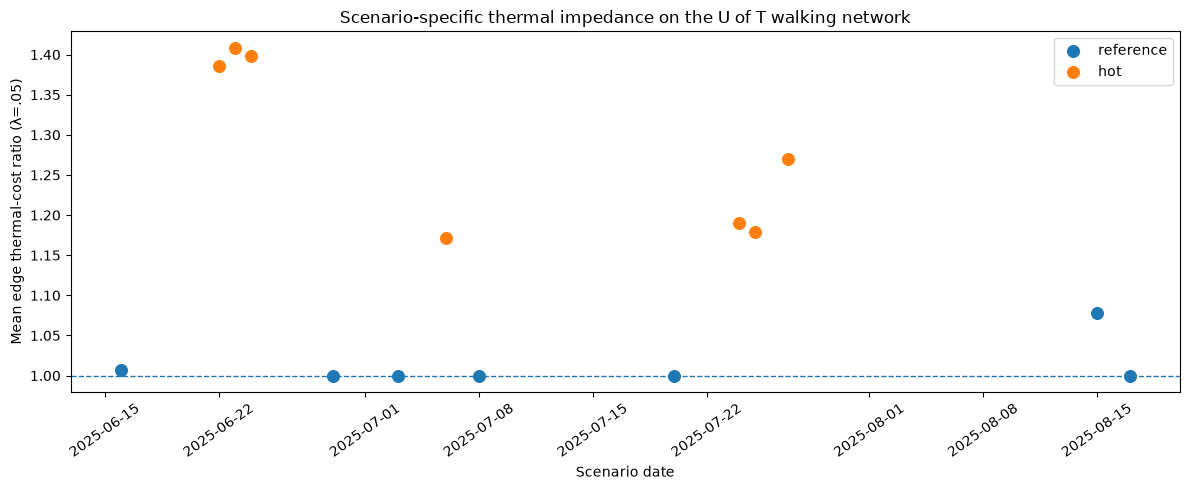

In [12]:
plot_df = (
    network_summary
    .sort_values(
        "date"
    )
    .copy()
)

fig, ax = plt.subplots(
    figsize=(12, 5)
)

for role in [
    "reference",
    "hot",
]:

    subset = plot_df[
        plot_df[
            "scenario_role"
        ] == role
    ]

    ax.scatter(
        subset[
            "date"
        ],
        subset[
            "mean_cost_ratio_lambda_005"
        ],
        s=70,
        label=role,
    )

ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel(
    "Scenario date"
)

ax.set_ylabel(
    "Mean edge thermal-cost ratio (λ=.05)"
)

ax.set_title(
    "Scenario-specific thermal impedance on the U of T walking network"
)

ax.legend()

plt.xticks(
    rotation=35
)

plt.tight_layout()
plt.show()

## 13. Spatial heterogeneity diagnostic

Paper 4 needs more than uniform network inflation.

This figure tests whether hotter scenarios also produce meaningfully different
**spatial variation** in edge-level thermal cost.

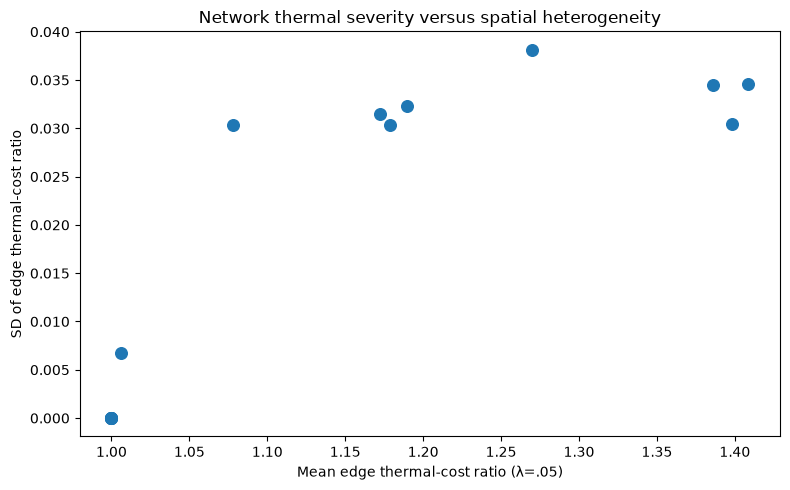

In [13]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.scatter(
    network_summary[
        "mean_cost_ratio_lambda_005"
    ],
    network_summary[
        "sd_cost_ratio_lambda_005"
    ],
    s=70,
)

ax.set_xlabel(
    "Mean edge thermal-cost ratio (λ=.05)"
)

ax.set_ylabel(
    "SD of edge thermal-cost ratio"
)

ax.set_title(
    "Network thermal severity versus spatial heterogeneity"
)

plt.tight_layout()
plt.show()

## 14. Inspect saturation at the 32°C threshold

In [14]:
display(
    network_summary[
        [
            "scenario_id",
            "scenario_role",
            "edge_utci_mean_C",
            "edge_utci_sd_C",
            "share_network_length_above_32C",
            "mean_cost_ratio_lambda_005",
        ]
    ]
    .sort_values(
        "share_network_length_above_32C",
        ascending=False,
    )
)

,scenario_id,scenario_role,edge_utci_mean_C,edge_utci_sd_C,share_network_length_above_32C,mean_cost_ratio_lambda_005
0,hot_2025-06-22_1500,hot,39.718489,0.689882,1.000000,1.385924
2,hot_2025-06-23_1500,hot,40.170886,0.692376,1.000000,1.408544
4,hot_2025-06-24_1500,hot,39.968089,0.609743,1.000000,1.398404
12,hot_2025-07-27_1500,hot,37.401904,0.767374,0.999600,1.270127
10,hot_2025-07-25_1500,hot,35.577719,0.614635,0.999465,1.178952
8,hot_2025-07-24_1500,hot,35.796123,0.666301,0.997965,1.189955
6,hot_2025-07-06_1500,hot,35.435119,0.663663,0.995840,1.172020
11,reference_2025-08-15_1500,reference,33.375391,1.215749,0.918224,1.077793
3,reference_2025-06-16_1500,reference,31.850196,0.850868,0.702757,1.006348
1,reference_2025-06-29_1500,reference,30.454570,0.930994,0.000000,1.000000


## 15. Final diagnostics

In [15]:
print(
    "Requested scenarios:",
    len(
        scenarios
    ),
)

print(
    "Thermal networks created:",
    len(
        network_summary
    ),
)

print()

if len(
    network_summary
) > 0:

    print(
        "Mean edge UTCI range:",
        round(
            network_summary[
                "edge_utci_mean_C"
            ].min(),
            2,
        ),
        "to",
        round(
            network_summary[
                "edge_utci_mean_C"
            ].max(),
            2,
        ),
        "°C",
    )

    print(
        "Mean λ=.05 cost ratio range:",
        round(
            network_summary[
                "mean_cost_ratio_lambda_005"
            ].min(),
            3,
        ),
        "to",
        round(
            network_summary[
                "mean_cost_ratio_lambda_005"
            ].max(),
            3,
        ),
    )

    print(
        "Spatial cost-ratio SD range:",
        round(
            network_summary[
                "sd_cost_ratio_lambda_005"
            ].min(),
            3,
        ),
        "to",
        round(
            network_summary[
                "sd_cost_ratio_lambda_005"
            ].max(),
            3,
        ),
    )

    print(
        "Share network >32°C range:",
        round(
            network_summary[
                "share_network_length_above_32C"
            ].min(),
            3,
        ),
        "to",
        round(
            network_summary[
                "share_network_length_above_32C"
            ].max(),
            3,
        ),
    )

Requested scenarios: 14
Thermal networks created: 14

Mean edge UTCI range: 26.52 to 40.17 °C
Mean λ=.05 cost ratio range: 1.0 to 1.409
Spatial cost-ratio SD range: 0.0 to 0.038
Share network >32°C range: 0.0 to 1.0


## Next step — Notebook 14

Notebook 14 should recompute accessibility for **every scenario-specific thermal
graph** using the same:

- origin nodes;
- transit destinations;
- 10-minute generalized walking budget;
- λ sensitivity values.

The resulting panel will finally allow us to compare:

**thermal scenario → network impedance → accessibility loss → observed Bike Share response**

across multiple hot and reference days.